# Média, Mediana, Moda e Máxima

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

## Imagem de exemplo


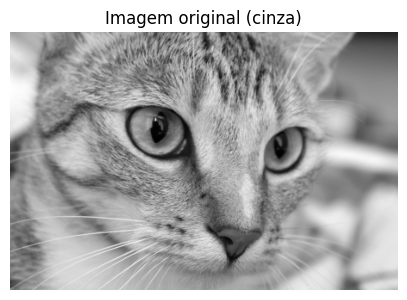

In [2]:
img_rgb = data.cat()
img = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(5, 5))
plt.imshow(img, cmap='gray')
plt.title('Imagem original (cinza)')
plt.axis('off')
plt.show()

## Convolução manual

Desliza o kernel sobre a imagem e soma o produto elemento a elemento. `np.pad` só replica a borda. Usada só no filtro de média (o único linear), os outros usam janela deslizante sem kernel.

In [3]:
def convolucao_manual(imagem, kernel):
    altura_k, largura_k = kernel.shape
    pad_h = altura_k // 2
    pad_w = largura_k // 2

    imagem_pad = np.pad(imagem, ((pad_h, pad_h), (pad_w, pad_w)), mode='edge')
    altura, largura = imagem.shape
    saida = np.zeros((altura, largura), dtype=np.float64)

    for i in range(altura):
        for j in range(largura):
            regiao = imagem_pad[i:i + altura_k, j:j + largura_k]
            saida[i, j] = np.sum(regiao * kernel)

    return np.clip(saida, 0, 255).astype(np.uint8)

## Janela deslizante genérica (filtros não-lineares)

Percorre a imagem, recorta a janela e aplica a estatística (mediana, moda, máximo) que eu passar.

In [4]:
def janela_deslizante(imagem, tamanho, funcao_estatistica):
    pad = tamanho // 2
    imagem_pad = np.pad(imagem, ((pad, pad), (pad, pad)), mode='edge')
    altura, largura = imagem.shape
    saida = np.zeros((altura, largura), dtype=np.float64)

    for i in range(altura):
        for j in range(largura):
            regiao = imagem_pad[i:i + tamanho, j:j + tamanho]
            saida[i, j] = funcao_estatistica(regiao)

    return np.clip(saida, 0, 255).astype(np.uint8)

## Filtro de média

Linear. Cada pixel vira a média da vizinhança (kernel de 1's normalizado, soma = 1).

In [5]:
def filtro_media(imagem, tamanho=3):
    kernel = np.ones((tamanho, tamanho), dtype=np.float64) / (tamanho * tamanho)
    return convolucao_manual(imagem, kernel)

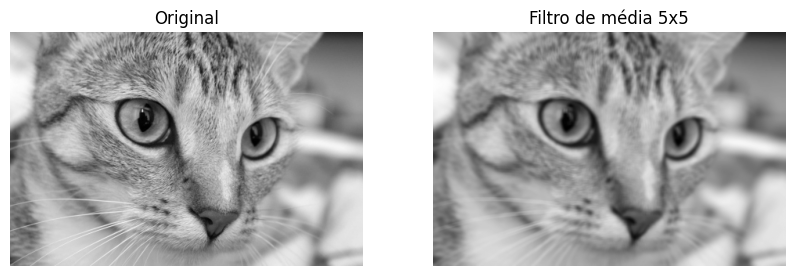

In [6]:
img_media = filtro_media(img, tamanho=5)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_media, cmap='gray')
plt.title('Filtro de média 5x5')
plt.axis('off')

plt.show()

Imagem mais borrada: filtro de média não preserva bordas.

## Filtro de mediana

Não-linear. Ordena os valores da janela e pega o do meio (`np.median`).

In [7]:
def filtro_mediana(imagem, tamanho=3):
    return janela_deslizante(imagem, tamanho, lambda regiao: np.median(regiao))

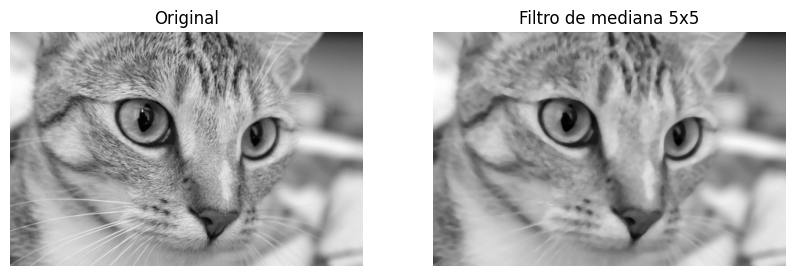

In [8]:
img_mediana = filtro_mediana(img, tamanho=5)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_mediana, cmap='gray')
plt.title('Filtro de mediana 5x5')
plt.axis('off')

plt.show()

Suaviza e preserva bordas melhor que a média.

## Filtro de moda

Não-linear. Troca o pixel pelo valor mais frequente na janela (`np.unique` + `argmax` das contagens).

In [9]:
def calcular_moda(regiao):
    valores, contagens = np.unique(regiao, return_counts=True)
    return valores[np.argmax(contagens)]


def filtro_moda(imagem, tamanho=3):
    return janela_deslizante(imagem, tamanho, calcular_moda)

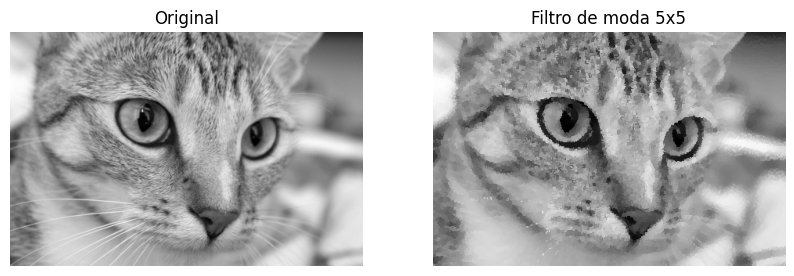

In [10]:
img_moda = filtro_moda(img, tamanho=5)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_moda, cmap='gray')
plt.title('Filtro de moda 5x5')
plt.axis('off')

plt.show()

Pouco efeito: em foto real quase não há tons repetidos numa janela 5x5.

## Filtro de máxima

Não-linear. Troca o pixel pelo maior valor da janela.

In [11]:
def filtro_maxima(imagem, tamanho=3):
    return janela_deslizante(imagem, tamanho, lambda regiao: np.max(regiao))

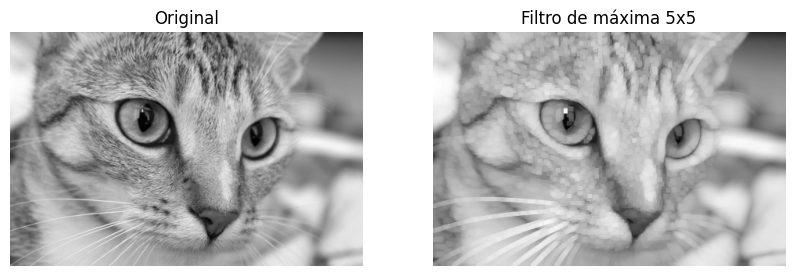

In [12]:
img_maxima = filtro_maxima(img, tamanho=5)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_maxima, cmap='gray')
plt.title('Filtro de máxima 5x5')
plt.axis('off')

plt.show()

Imagem mais clara, regiões escuras encolhem.

## Comparação final

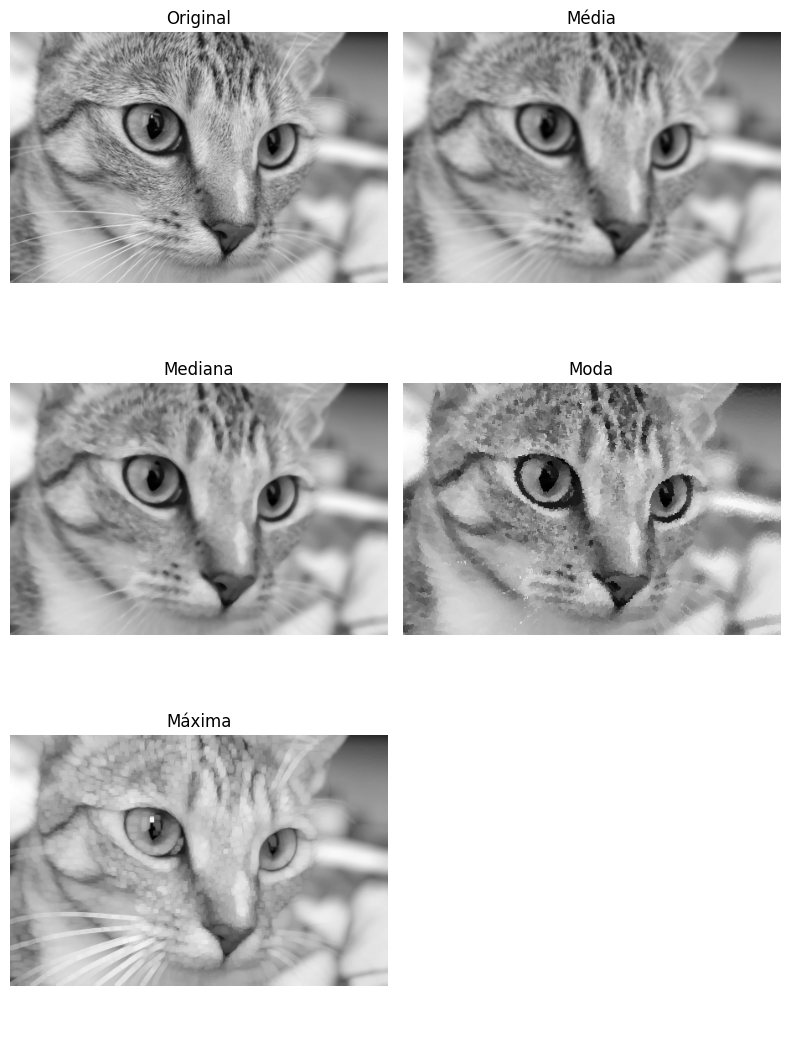

In [13]:
imagens = [img, img_media, img_mediana, img_moda, img_maxima]
titulos = ['Original', 'Média', 'Mediana', 'Moda', 'Máxima']

fig, eixos = plt.subplots(3, 2, figsize=(8, 11))
eixos = eixos.ravel()

for eixo, imagem, titulo in zip(eixos, imagens, titulos):
    eixo.imshow(imagem, cmap='gray')
    eixo.set_title(titulo)
    eixo.axis('off')

eixos[-1].axis('off')

plt.tight_layout()
plt.show()

**Conclusão:** média e mediana suavizam, mas mediana preserva bordas melhor. Moda quase não muda a foto (poucos tons repetidos); brilha em máscaras/rótulos. Máxima clareia a imagem e reduz áreas escuras.